# Air raid alerts in Kyiv City: time series analysis and a next-day forecast

**Question.** How has the daily time under air raid alert in Kyiv City evolved, what regular patterns does it have, and can tomorrow's alert-hours be forecast better than simple baselines?

**Data.** Official alerts file from `Vadimkin/ukrainian-air-raid-sirens-dataset`, commit `bf0c323c`, `datasets/official_data_en.csv`. Cleaning rules and assumptions are in the README.

**Main series.** Hours under alert per calendar day (Europe/Kyiv), built as the union of alert intervals, 2022-03-16 to 2026-08-28.

**Summary of findings** (details and caveats in each section):

1. No monotonic trend. Alert time moves in multi-month waves around a mean of about 1.6 h/day.
2. A strong hour-of-day pattern (nights), no detectable day-of-week pattern, and no reliable yearly pattern.
3. Day-to-day autocorrelation is weak (lag 1 about 0.13). The series has no unit root, but its mean level drifts.
4. STL attributes close to 90% of the variance to the remainder; the weekly component is negligible.
5. No shift in the Kyiv City series can be attributed to the raion-level switch.
6. Kharkivska oblast rises from about 11 to about 20 h/day across the switch, but the definition loosens at the same time, so the rise cannot be read as a change in threat.
7. **Forecast v1 (next-day alert-hours): weak result.** No method beats a constant. The models win on MAE only by predicting a near-constant low value, and lose on RMSE.
8. **Lead-lag.** Alerts in the surrounding oblasts are correlated with Kyiv City's (up to 0.51) but the peak is at lag zero: they mostly start together. There is a slight asymmetry in favour of the neighbours leading.
9. **Forecast v2 (alert within 15 to 180 minutes): small, real signal at short leads.** Knowing the neighbours' alert state improves the Brier score by about 3 to 4% over Kyiv City's own history at leads up to 60 minutes. At 120 and 180 minutes the gain is not distinguishable from zero.
10. **Forecast v3 (any alert per 6-hour block tomorrow): no skill.** The selected trailing-window rate does not beat the all-history rate.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import acf, adfuller, kpss

from src import forecast, load, series

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, MUTED, GRID, LIGHT = "#0b0b0b", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": LIGHT, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "axes.labelsize": 9,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 2,
})
pd.set_option("display.width", 160, "display.precision", 3)

SWITCH_DONE = pd.Timestamp("2025-11-05")      # oblast-level rows have ceased outside Kyiv City
TRANSITION_START = pd.Timestamp("2025-08-01")  # share of oblast-level rows starts to fall
SEASONAL_START = "2024-01-01"

def mark_switch(ax, label=True):
    ax.axvspan(TRANSITION_START, SWITCH_DONE, color=LIGHT, alpha=0.35, lw=0)
    ax.axvline(SWITCH_DONE, color=INK, lw=1, ls="--")
    if label:
        ax.annotate("raion-level\nswitch complete", (SWITCH_DONE, 1), xycoords=("data", "axes fraction"),
                    xytext=(4, -2), textcoords="offset points", va="top", fontsize=8, color="#52514e")

## Data checks

The same checks run in `tests/test_load.py`. Printed here so the report is self-contained.

In [2]:
raw = load.read_raw()
report = load.validate_raw(raw)
alerts = load.clean(raw)
brk = report["feed_break"]
checks = pd.Series({
    "rows in raw file": report["rows"],
    "first / last alert start (UTC)": f"{report['first_start']:%Y-%m-%d} / {report['last_start']:%Y-%m-%d}",
    "sorted by start": report["sorted_by_start"],
    "exact duplicate rows (dropped)": f"{report['duplicate_rows']} ({report['duplicate_share']:.1%})",
    "finished_at <= started_at (dropped)": f"{report['nonpositive_duration_raw']} raw, {report['nonpositive_duration_dedup']} unique",
    "alerts > 24 h (raw / unique)": f"{report['over_24h_raw']} / {report['over_24h_dedup']}",
    "longest alert, hours": round(report["max_duration_h"], 1),
    "longest alert by region, hours": {k: round(v, 1) for k, v in report["max_duration_h_by_region"].items()},
    "rows on 2026-08-30..09-01 (UTC)": sum(report["rows_on_gap_days_utc"].values()),
    "rows on 2026-08-29 (UTC)": report["rows_on_2026_08_29_utc"],
    "last start before feed break (UTC)": f"{brk['last_start_before']:%Y-%m-%d %H:%M}",
    "feed break length": str(brk["gap"]),
    "next-longest nationwide silence": str(brk["second_longest_gap"]),
    "last complete Kyiv day": brk["last_complete_day"],
    "Kyiv City levels": report["kyiv_city_levels"],
    "last oblast-level row outside Kyiv City": f"{report['last_oblast_level_row_outside_kyiv_city']:%Y-%m-%d}",
    "rows after cleaning": len(alerts),
})
print(checks.to_string())
print("\nShare of oblast-level rows by month:", report["oblast_level_row_share_by_month"])

rows in raw file                                                                      299275
first / last alert start (UTC)                                       2022-03-15 / 2026-09-07
sorted by start                                                                        False
exact duplicate rows (dropped)                                                113845 (38.0%)
finished_at <= started_at (dropped)                                          4 raw, 2 unique
alerts > 24 h (raw / unique)                                                      1318 / 897
longest alert, hours                                                                 14497.3
longest alert by region, hours             {'Kyiv City': 11.2, 'Kharkivska oblast': 14497...
rows on 2026-08-30..09-01 (UTC)                                                            0
rows on 2026-08-29 (UTC)                                                                  88
last start before feed break (UTC)                                    

In [3]:
kyiv = series.region_daily(alerts, "Kyiv City")
kyiv_hourly = series.region_hourly(alerts, "Kyiv City", first_day=SEASONAL_START)
recent = kyiv[SEASONAL_START:]

print(f"daily series: {kyiv.index[0]:%Y-%m-%d} .. {kyiv.index[-1]:%Y-%m-%d}, {len(kyiv)} days, no missing days: {not kyiv.isna().any()}")
print(f"sanity totals: Feb 2025 = {kyiv['2025-02'].sum():.2f} h; Aug 2026 (to the 28th) = {kyiv['2026-08'].sum():.2f} h")
print(f"hourly and daily series agree: {np.isclose(kyiv_hourly.sum(), recent.sum())}")
print(f"mean {kyiv.mean():.2f} h/day, median {kyiv.median():.2f}, days with no alert {(kyiv == 0).mean():.0%}, max {kyiv.max():.1f} h on {kyiv.idxmax():%Y-%m-%d}")

daily series: 2022-03-16 .. 2026-08-28, 1627 days, no missing days: True
sanity totals: Feb 2025 = 121.78 h; Aug 2026 (to the 28th) = 74.97 h
hourly and daily series agree: True
mean 1.59 h/day, median 0.77, days with no alert 29%, max 14.6 h on 2026-08-27


The Aug 2026 total is about 75 h rather than the 80 h from the initial profiling. The difference is 4.5 h on 2026-08-29, which is discarded as a partial day.

Clock-change days are 23 or 25 hours long and are left as they are. A day's value is elapsed hours under alert, not a share of the day.

## 1. Trend over the full history

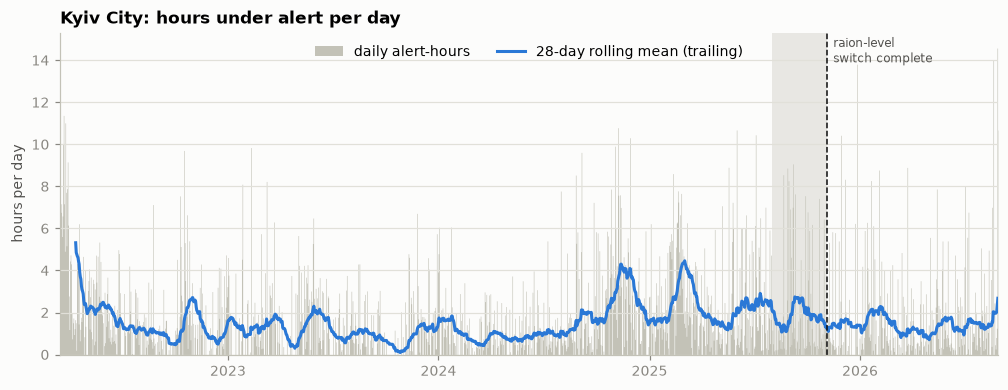

      mean  median    max  share_zero_days  days
2022  1.84    1.20  13.33             0.26   291
2023  1.10    0.28   9.85             0.47   365
2024  1.48    0.72  10.79             0.28   366
2025  2.03    1.12  13.81             0.19   365
2026  1.54    0.64  14.58             0.25   240

28-day mean: lowest 0.09 h/day (window ending 2023-10-27), highest 5.32 (window ending 2022-04-12)


In [4]:
rolling = kyiv.rolling(28).mean()
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.fill_between(kyiv.index, 0, kyiv.values, color=LIGHT, lw=0, step="mid", label="daily alert-hours")
ax.plot(rolling.index, rolling.values, color=BLUE, label="28-day rolling mean (trailing)")
mark_switch(ax)
ax.set(title="Kyiv City: hours under alert per day", ylabel="hours per day", ylim=(0, None), xlim=(kyiv.index[0], kyiv.index[-1]))
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend(loc="upper center", ncol=2)
plt.show()

by_year = kyiv.groupby(kyiv.index.year).agg(mean="mean", median="median", max="max", share_zero_days=lambda s: (s == 0).mean(), days="size")
print(by_year.round(2).to_string())
print(f"\n28-day mean: lowest {rolling.min():.2f} h/day (window ending {rolling.idxmin():%Y-%m-%d}), highest {rolling.max():.2f} (window ending {rolling.idxmax():%Y-%m-%d})")

There is no steady rise or fall. The 28-day mean ranges from about 0.1 h/day (autumn 2023) to about 5 h/day (spring 2022 and early 2025), in waves that last a few months. 2023 was the quietest year and 2025 the heaviest. 2022 and 2026 are partial years, so their rows are not full-year figures.

The daily values are heavily right-skewed: about 3 in 10 days have no alert at all, and a few days exceed 10 hours.

## 2. Seasonality (2024-01-01 onward)

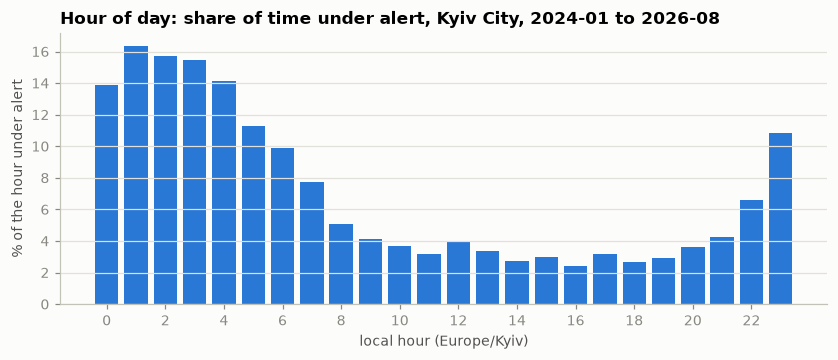

00:00-05:59 average 14.5% of the time under alert; 10:00-19:59 average 3.1%


In [5]:
def hac_wald(y, X, tested, lags):
    # OLS with Newey-West errors; joint F-test that the `tested` coefficients are all zero
    res = sm.OLS(y, sm.add_constant(X)).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    names = list(res.params.index)
    R = np.zeros((len(tested), len(names)))
    for i, name in enumerate(tested):
        R[i, names.index(name)] = 1
    test = res.wald_test(R, scalar=True, use_f=True)
    return res, float(test.statistic), float(test.pvalue)

hour_share = kyiv_hourly.groupby(kyiv_hourly.index.hour).mean() * 100
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(hour_share.index, hour_share.values, width=0.8, color=BLUE)
ax.set(title="Hour of day: share of time under alert, Kyiv City, 2024-01 to 2026-08",
       xlabel="local hour (Europe/Kyiv)", ylabel="% of the hour under alert", xticks=range(0, 24, 2))
plt.show()
print(f"00:00-05:59 average {hour_share.loc[0:5].mean():.1f}% of the time under alert; 10:00-19:59 average {hour_share.loc[10:19].mean():.1f}%")

The hour-of-day pattern is strong. Between midnight and 06:00 the city is under alert about 14% of the time, against about 3% between 10:00 and 20:00 (a factor of about 4.5). This is the clearest regularity in the data, but it is within-day and does not help a daily forecast.

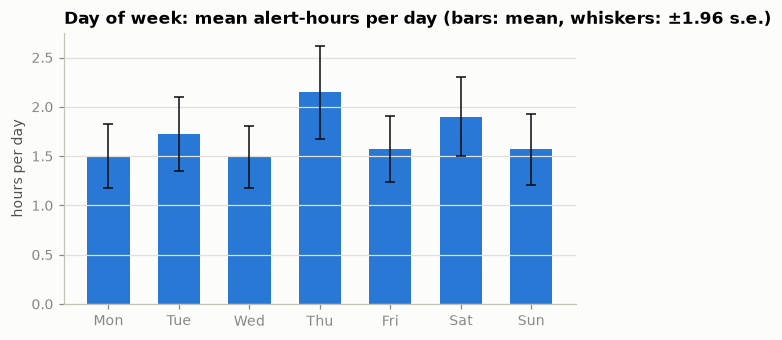

joint test that all weekdays have the same mean (HAC, 14 lags): F = 1.50, p = 0.174


In [6]:
names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
dow_mean = recent.groupby(recent.index.dayofweek).mean()
dow_sem = recent.groupby(recent.index.dayofweek).sem()
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(names, dow_mean.values, width=0.6, color=BLUE)
ax.errorbar(names, dow_mean.values, yerr=1.96 * dow_sem.values, fmt="none", ecolor=INK, elinewidth=1, capsize=3)
ax.set(title="Day of week: mean alert-hours per day (bars: mean, whiskers: ±1.96 s.e.)", ylabel="hours per day")
plt.show()

dummies = pd.get_dummies(recent.index.dayofweek, prefix="dow", drop_first=True, dtype=float).set_index(recent.index)
_, f_dow, p_dow = hac_wald(recent, dummies, list(dummies.columns), lags=14)
print(f"joint test that all weekdays have the same mean (HAC, 14 lags): F = {f_dow:.2f}, p = {p_dow:.3f}")

No day-of-week pattern is detectable. Weekday means range from 1.5 to 2.2 h/day, the intervals overlap, and the joint test does not reject equal means (p about 0.17).

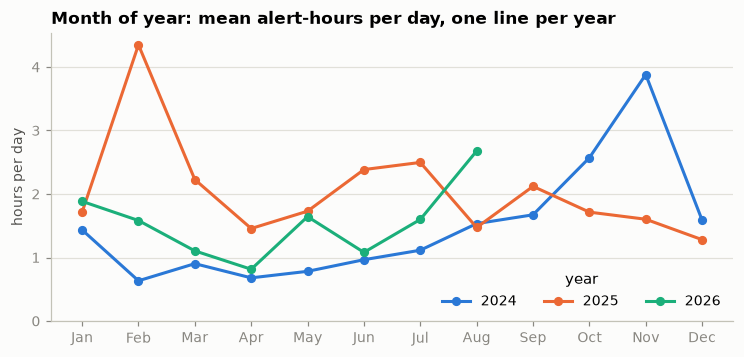

    2024  2025  2026
1   1.43  1.71  1.88
2   0.63  4.35  1.58
3   0.90  2.23  1.10
4   0.68  1.46  0.81
5   0.78  1.73  1.64
6   0.97  2.38  1.08
7   1.11  2.50  1.60
8   1.53  1.47  2.68
9   1.67  2.12   NaN
10  2.57  1.71   NaN
11  3.88  1.60   NaN
12  1.59  1.28   NaN

Spearman rank correlation of monthly means between years:
  2024 vs 2025: rho = -0.39  (12 months in common)
  2025 vs 2026: rho = -0.14  (8 months in common)
  2024 vs 2026: rho = +0.64  (8 months in common)
annual harmonic, regressors ['sin', 'cos']: F = 3.05, p = 0.048, R^2 = 0.019
annual harmonic, regressors ['sin', 'cos', 'years_since_start']: F = 2.92, p = 0.054, R^2 = 0.021


autocorrelation at lag 365: -0.059  (approx. 95% band ±0.063)


In [7]:
monthly = recent.groupby([recent.index.month, recent.index.year]).mean().unstack()
fig, ax = plt.subplots(figsize=(8, 3.4))
for year, colour in zip(monthly.columns, [BLUE, ORANGE, AQUA]):
    ax.plot(monthly.index, monthly[year], color=colour, marker="o", ms=5, label=str(year))
ax.set(title="Month of year: mean alert-hours per day, one line per year", ylabel="hours per day",
       xticks=range(1, 13), xticklabels=["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"], ylim=(0, None))
ax.legend(title="year", ncol=3)
plt.show()
print(monthly.round(2).to_string())

# Does a yearly pattern exist?  (a) do the years agree on which months are heavy?
print("\nSpearman rank correlation of monthly means between years:")
for a, b in [(2024, 2025), (2025, 2026), (2024, 2026)]:
    pair = monthly[[a, b]].dropna()
    print(f"  {a} vs {b}: rho = {pair[a].corr(pair[b], method='spearman'):+.2f}  ({len(pair)} months in common)")

# (b) annual sine/cosine in a regression with autocorrelation-robust errors
doy = recent.index.dayofyear
harmonics = pd.DataFrame({"sin": np.sin(2 * np.pi * doy / 365.25), "cos": np.cos(2 * np.pi * doy / 365.25),
                          "years_since_start": np.arange(len(recent)) / 365.25}, index=recent.index)
for cols in (["sin", "cos"], ["sin", "cos", "years_since_start"]):
    res, f_year, p_year = hac_wald(recent, harmonics[cols], ["sin", "cos"], lags=28)
    print(f"annual harmonic, regressors {cols}: F = {f_year:.2f}, p = {p_year:.3f}, R^2 = {res.rsquared:.3f}")

# (c) autocorrelation one year apart
rho = acf(recent, nlags=366)
print(f"autocorrelation at lag 365: {rho[365]:+.3f}  (approx. 95% band ±{1.96 / np.sqrt(len(recent)):.3f})")

**There is no reliable yearly pattern.** The three checks agree:

- The years disagree on which months are heavy. 2024 peaks in October–November, 2025 peaks in February and June–July, and the rank correlation between 2024 and 2025 is negative (about −0.4).
- An annual sine/cosine term is borderline (p about 0.05) and explains about 2% of the variance.
- The autocorrelation at a lag of one year is inside the noise band (about −0.06).

With 2.7 annual cycles this cannot rule out a small yearly effect. It does mean that the month-of-year averages are dominated by individual campaigns, so no yearly term is used in the decomposition or the forecast.

## 3. Autocorrelation and stationarity

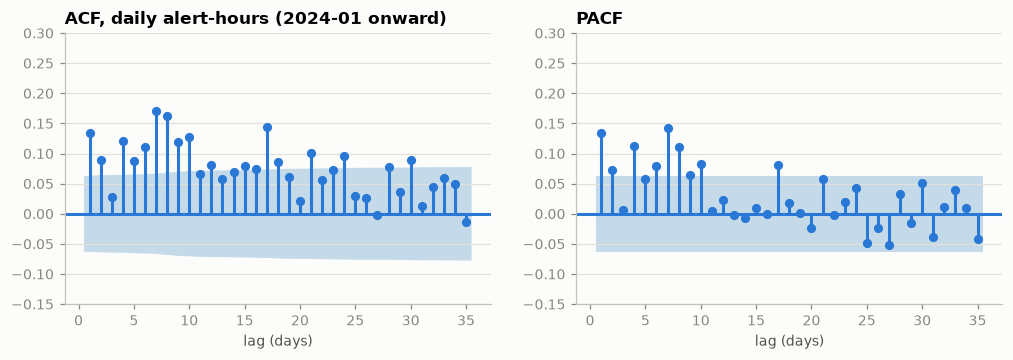

ACF lags 1-8: [0.134 0.089 0.027 0.12  0.087 0.111 0.17  0.162]
                days  ADF stat  ADF p  ADF lags  KPSS stat  KPSS p  KPSS lags
series                                                                       
full history    1627    -8.190    0.0         9      0.423   0.067         20
2024-01 onward   971    -5.154    0.0         9      0.586   0.024         11


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
plot_acf(recent, lags=35, ax=axes[0], zero=False, color=BLUE, vlines_kwargs={"colors": BLUE}, title="ACF, daily alert-hours (2024-01 onward)")
plot_pacf(recent, lags=35, ax=axes[1], zero=False, method="ywm", color=BLUE, vlines_kwargs={"colors": BLUE}, title="PACF")
for ax in axes:
    ax.set(xlabel="lag (days)", ylim=(-0.15, 0.3))
plt.show()
print("ACF lags 1-8:", np.round(rho[1:9], 3))

rows = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # KPSS warns when p is outside its lookup table
    for label, values in [("full history", kyiv), ("2024-01 onward", recent)]:
        adf_stat, adf_p, adf_lags = adfuller(values, autolag="AIC")[:3]
        kpss_stat, kpss_p, kpss_lags = kpss(values, regression="c", nlags="auto")[:3]
        rows.append({"series": label, "days": len(values), "ADF stat": adf_stat, "ADF p": adf_p, "ADF lags": adf_lags,
                     "KPSS stat": kpss_stat, "KPSS p": kpss_p, "KPSS lags": kpss_lags})
print(pd.DataFrame(rows).set_index("series").round(3).to_string())

Autocorrelation is positive but small at every lag: about 0.13 at lag 1 and never above 0.17. It decays slowly rather than cutting off, which fits a slowly drifting level with large day-to-day noise on top. Lag 7 is the largest value, but lag 8 is almost the same, so this is not a clean weekly spike.

The two tests answer different questions and the result is mixed:

- **ADF** (null: unit root) rejects strongly in both samples. The series does not behave like a random walk.
- **KPSS** (null: stationary around a constant level) rejects at 5% for 2024 onward (p about 0.02) and is borderline for the full history (p about 0.07). The mean level is not constant.

So the series is best described as mean-reverting noise around a level that shifts over months, which is what the plot in section 1 shows.

## 4. STL decomposition

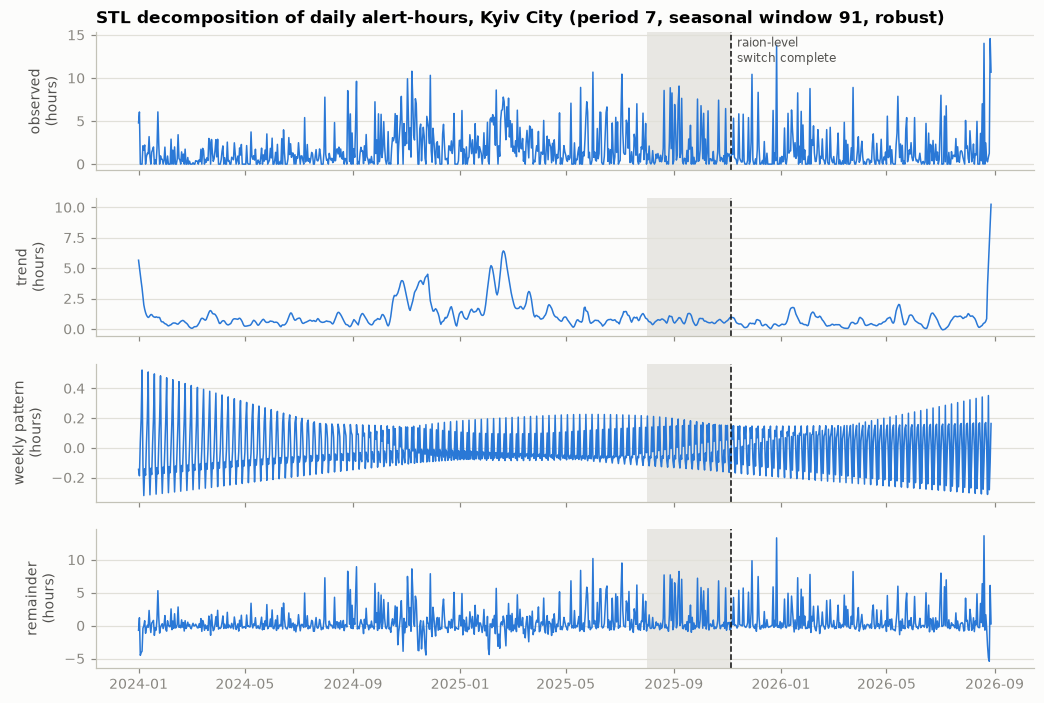

variance relative to the observed series: trend 23%, weekly 0%, remainder 87%
strength of trend 0.13, strength of weekly pattern 0.01  (0 = none, 1 = dominant)
weekly component range: -0.32 to +0.52 h
for comparison, statsmodels' default seasonal window (7): weekly 21% of variance, range -3.0 to +11.0 h


In [9]:
STL_SEASONAL_WINDOW = 91  # the weekly shape may change over about a quarter, not week to week
stl = STL(recent, period=7, seasonal=STL_SEASONAL_WINDOW, robust=True).fit()
fig, axes = plt.subplots(4, 1, figsize=(11, 7.5), sharex=True)
for ax, (label, values) in zip(axes, [("observed", recent), ("trend", stl.trend), ("weekly pattern", stl.seasonal), ("remainder", stl.resid)]):
    ax.plot(values.index, values.values, color=BLUE, lw=1)
    ax.set_ylabel(f"{label}\n(hours)")
    mark_switch(ax, label=(label == "observed"))
axes[0].set_title("STL decomposition of daily alert-hours, Kyiv City (period 7, seasonal window 91, robust)")
plt.show()

total = recent.var()
strength_week = max(0, 1 - stl.resid.var() / (stl.resid + stl.seasonal).var())
strength_trend = max(0, 1 - stl.resid.var() / (stl.resid + stl.trend).var())
print(f"variance relative to the observed series: trend {stl.trend.var() / total:.0%}, weekly {stl.seasonal.var() / total:.0%}, remainder {stl.resid.var() / total:.0%}")
print(f"strength of trend {strength_trend:.2f}, strength of weekly pattern {strength_week:.2f}  (0 = none, 1 = dominant)")
print(f"weekly component range: {stl.seasonal.min():+.2f} to {stl.seasonal.max():+.2f} h")

default = STL(recent, period=7, robust=True).fit()
print(f"for comparison, statsmodels' default seasonal window (7): weekly {default.seasonal.var() / total:.0%} of variance, range {default.seasonal.min():+.1f} to {default.seasonal.max():+.1f} h")

The remainder dominates: it carries close to 90% of the variance. The trend component (about a quarter of the variance) reproduces the multi-month waves from section 1. The shares do not sum to 100% because the components are not exactly uncorrelated.

The weekly pattern is negligible: under 1% of the variance and within about ±0.5 h, which agrees with the day-of-week test in section 2.

This depends on one setting, the seasonal smoothing window. With the statsmodels default of 7, the weekly component is allowed to change every week and absorbs individual spikes, reaching about +11 h and 21% of the variance. That is fitted noise rather than a weekly cycle, so a window of 91 days is used here.

The decomposition uses 2024-01-01 onward, to match section 2 and the forecast.

## 5. Structural change at the raion-level switch

The switch was phased. The share of oblast-level rows fell from 58% in July 2025 to 2% in November 2025, and outside Kyiv City the last oblast-level row is dated 2025-11-04. The plots shade August to early November 2025 as the transition and mark 2025-11-05 as its end.

Kyiv City has only oblast-level rows throughout, so the way its alerts are recorded did not change.

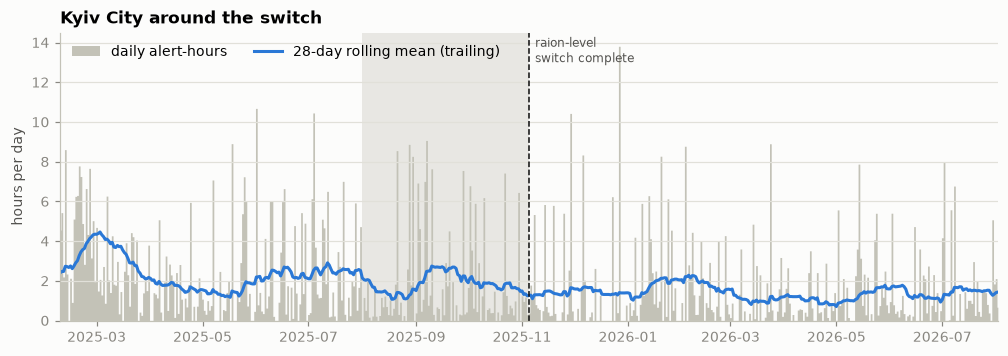

           mean before  mean after  difference  95% low  95% high     p
window                                                                 
±90 days          1.80        1.59       -0.21    -0.94      0.52  0.58
±180 days         1.99        1.40       -0.59    -1.07     -0.10  0.02
180 days before: 1.42 alerts per day, median duration 0.52 h, mean 1.40 h
180 days after: 1.31 alerts per day, median duration 0.53 h, mean 1.07 h
same calendar window a year apart: 2024-11-05..2025-05-03 mean 2.42 h/day; 2025-11-05..2026-05-03 mean 1.40 h/day


In [10]:
window = kyiv[SWITCH_DONE - pd.Timedelta(days=270): SWITCH_DONE + pd.Timedelta(days=270)]
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.fill_between(window.index, 0, window.values, color=LIGHT, lw=0, step="mid", label="daily alert-hours")
ax.plot(window.index, kyiv.rolling(28).mean()[window.index], color=BLUE, label="28-day rolling mean (trailing)")
mark_switch(ax)
ax.set(title="Kyiv City around the switch", ylabel="hours per day", ylim=(0, None), xlim=(window.index[0], window.index[-1]))
ax.legend(loc="upper left", ncol=2)
plt.show()

rows = []
for half in (90, 180):
    part = kyiv[SWITCH_DONE - pd.Timedelta(days=half): SWITCH_DONE + pd.Timedelta(days=half - 1)]
    step = pd.DataFrame({"after": (part.index >= SWITCH_DONE).astype(float)}, index=part.index)
    res = sm.OLS(part, sm.add_constant(step)).fit(cov_type="HAC", cov_kwds={"maxlags": 14})
    low, high = res.conf_int().loc["after"]
    rows.append({"window": f"±{half} days", "mean before": part[part.index < SWITCH_DONE].mean(), "mean after": part[part.index >= SWITCH_DONE].mean(),
                 "difference": res.params["after"], "95% low": low, "95% high": high, "p": res.pvalues["after"]})
print(pd.DataFrame(rows).set_index("window").round(2).to_string())

kyiv_rows = series.region_rows(alerts, "Kyiv City")
local_start = kyiv_rows["started_at"].dt.tz_convert(load.KYIV_TZ).dt.tz_localize(None)
for label, mask in [("180 days before", (local_start >= SWITCH_DONE - pd.Timedelta(days=180)) & (local_start < SWITCH_DONE)),
                    ("180 days after", (local_start >= SWITCH_DONE) & (local_start < SWITCH_DONE + pd.Timedelta(days=180)))]:
    print(f"{label}: {mask.sum() / 180:.2f} alerts per day, median duration {kyiv_rows.loc[mask, 'duration_h'].median():.2f} h, mean {kyiv_rows.loc[mask, 'duration_h'].mean():.2f} h")
print(f"same calendar window a year apart: 2024-11-05..2025-05-03 mean {kyiv['2024-11-05':'2025-05-03'].mean():.2f} h/day; 2025-11-05..2026-05-03 mean {kyiv['2025-11-05':'2026-05-03'].mean():.2f} h/day")

**No shift in the Kyiv City series can be attributed to the switch.**

- With 90 days either side, the mean changes by about −0.2 h/day and the interval comfortably includes zero.
- With 180 days either side, the drop is about −0.6 h/day and nominally significant (p about 0.02). The result depends on the window: the "before" half then includes the heavy June–July 2025 wave, and the series was already falling before the transition began.
- The number of alerts per day and their median duration are almost the same on both sides (about 1.4 vs 1.3 per day, median about 0.5 h).

A change of this size is ordinary for this series; section 1 shows several larger moves with no change in recording. A before/after comparison cannot separate a recording effect from a real change in attacks, and because Kyiv City's recording did not change there is no mechanism for the former.

## 6. Regional comparison

For the two oblasts the series is "an alert is active anywhere in the oblast": the union of oblast-, raion- and hromada-level rows.

**The two periods are not directly comparable.** Before the switch, most alerts cover the whole oblast at once. After it, each raion is alerted separately, so the union counts time when any one raion is under alert, and the definition becomes looser (it can only add time, never remove it). A rise after the switch is partly or wholly a recording effect.

Alerts longer than 7 days are excluded from the oblast series. In Kharkivska this removes two standing hromada alerts (Lypetska, 2024-05-12 to 2026-01-06, and Vovchanska, 2024-05-20 to 2025-08-01). The dashed line shows the series with them included.

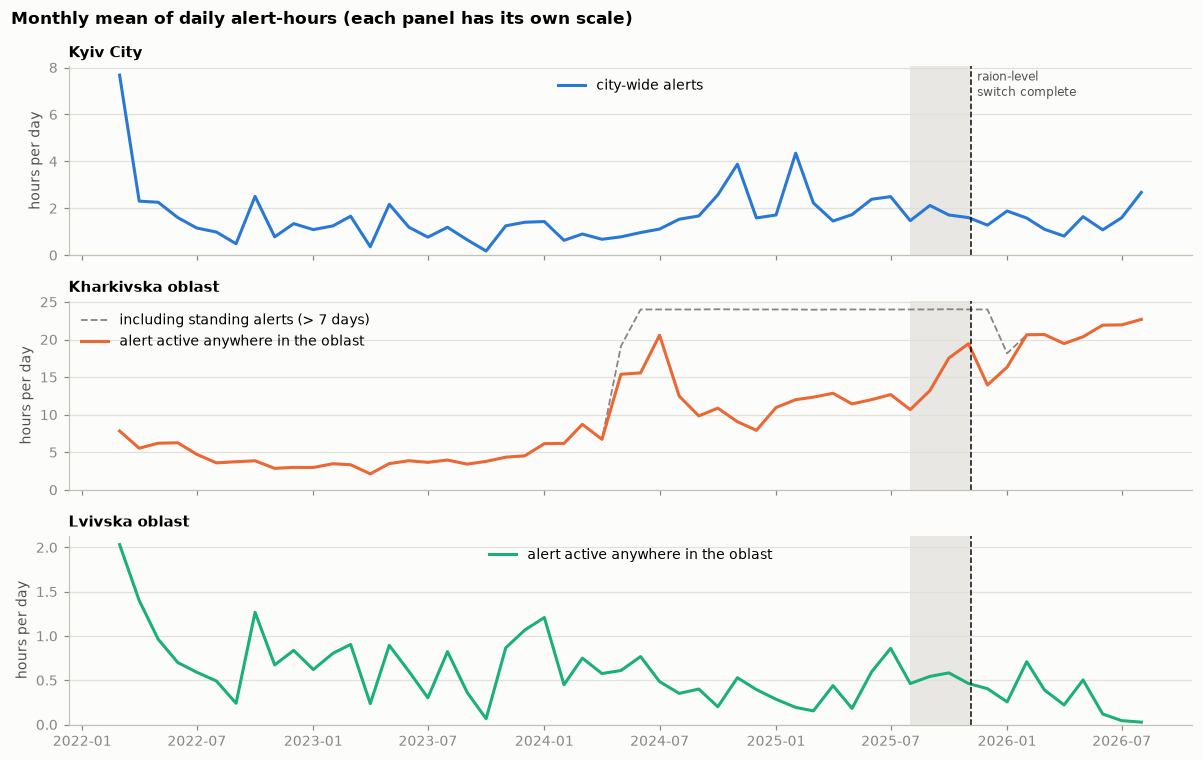

                                                Kyiv City  Kharkivska oblast  Lvivska oblast
2024-08-01..2025-07-31 (before the transition)       2.28              11.20            0.38
2025-11-05..2026-08-28 (after the switch)            1.53              19.69            0.32

rows by level, Kharkivska and Lvivska, before the transition vs after the switch:
  Kharkivska oblast: before {'oblast': 2069, 'hromada': 820, 'raion': 5}; after {'raion': 12584, 'hromada': 2139}
  Lvivska oblast: before {'oblast': 133}; after {'raion': 649}

correlation of daily series, 2024-01 onward:
                   Kyiv City  Kharkivska oblast  Lvivska oblast
Kyiv City               1.00               0.10            0.43
Kharkivska oblast       0.10               1.00            0.03
Lvivska oblast          0.43               0.03            1.00


In [11]:
regions = ["Kyiv City", "Kharkivska oblast", "Lvivska oblast"]
daily = pd.DataFrame({name: series.region_daily(alerts, name) for name in regions})
kharkiv_all = series.region_daily(alerts, "Kharkivska oblast", include_standing=True)
monthly_mean = daily.resample("MS").mean()

fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for ax, name, colour in zip(axes, regions, [BLUE, ORANGE, AQUA]):
    if name == "Kharkivska oblast":
        ax.plot(monthly_mean.index, kharkiv_all.resample("MS").mean(), color=MUTED, lw=1.2, ls="--", label="including standing alerts (> 7 days)")
    ax.plot(monthly_mean.index, monthly_mean[name], color=colour, label="alert active anywhere in the oblast" if name != "Kyiv City" else "city-wide alerts")
    ax.set(ylabel="hours per day", ylim=(0, None))
    ax.set_title(name, fontsize=10)
    ax.legend(loc="upper left" if name == "Kharkivska oblast" else "upper center")
    mark_switch(ax, label=(name == "Kyiv City"))
fig.suptitle("Monthly mean of daily alert-hours (each panel has its own scale)", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
plt.show()

periods = {"2024-08-01..2025-07-31 (before the transition)": daily["2024-08-01":"2025-07-31"],
           "2025-11-05..2026-08-28 (after the switch)": daily["2025-11-05":]}
print(pd.DataFrame({label: part.mean() for label, part in periods.items()}).round(2).T.to_string())
print("\nrows by level, Kharkivska and Lvivska, before the transition vs after the switch:")
for name in regions[1:]:
    rows = alerts[alerts["oblast"] == name]
    local = rows["started_at"].dt.tz_convert(load.KYIV_TZ).dt.tz_localize(None)
    before = rows[(local >= "2024-08-01") & (local < "2025-08-01")]["level"].value_counts().to_dict()
    after = rows[local >= SWITCH_DONE]["level"].value_counts().to_dict()
    print(f"  {name}: before {before}; after {after}")
print("\ncorrelation of daily series, 2024-01 onward:")
print(daily[SEASONAL_START:].corr().round(2).to_string())

- **Kharkivska oblast** is on a different scale from the other two: about 11 h/day in the year before the transition and about 20 h/day after the switch. The rise starts in October 2025, when Kharkivska's own oblast-level rows stop (the last is 2025-10-19). Because the definition loosens at the same moment, this analysis cannot say how much of the rise reflects more attacks.
- **Lvivska oblast** stays low, about 0.3–0.4 h/day in both periods. No increase is visible after the switch, although the looser definition would push it upward if anything.
- **Kyiv City** sits between them at 1.5–2.3 h/day and is the only series with a constant definition.

Daily Kyiv City and Lvivska values are moderately correlated (about 0.4), which fits country-wide alerts during large attacks. Kharkivska is almost uncorrelated with both.

Including the two standing alerts, Kharkivska is at 24 h/day from May 2024 to January 2026, which is why they are excluded here.

## Forecast v1: next-day alert-hours

- **Target:** Kyiv City alert-hours for day D, using only data up to the end of day D−1.
- **Training data:** 2024-01-01 onward.
- **Test:** rolling origin over the final 90 days, with every model refitted for each day.
- **Settings:** chosen on the 90 days before the test period, with parameters estimated on the data before that. Candidates and the selection table are printed below.
- **References:** two constants (training median and training mean) are included only to interpret the scores. They are not part of the requested comparison.

This cell refits two models 90 times and takes a few minutes.

In [12]:
result = forecast.evaluate(kyiv)
actual, predictions, scores = result["actual"], result["forecasts"], result["scores"]

print(f"training starts {forecast.TRAIN_START}; settings chosen with data up to {result['selection_cutoff']:%Y-%m-%d}")
print(f"test period {result['test_first_day']:%Y-%m-%d} .. {result['test_last_day']:%Y-%m-%d} ({len(actual)} days)\n")
print("exponential smoothing candidates (validation window = 90 days before the test period):")
print(result["ets_validation"].round(3).to_string())
print("chosen:", result["ets_settings"])
print("\nSARIMA candidates:")
print(result["sarima_validation"].round(3).to_string())
print("chosen:", result["sarima_settings"])

training starts 2024-01-01; settings chosen with data up to 2026-05-30
test period 2026-05-31 .. 2026-08-28 (90 days)

exponential smoothing candidates (validation window = 90 days before the test period):
   trend  damped_trend  seasonal    log  val_mae  val_rmse
0  False         False       NaN  False    1.255     1.742
1  False         False       7.0  False    1.240     1.720
2   True          True       NaN  False    1.256     1.741
3   True          True       7.0  False    1.240     1.720
4  False         False       NaN   True    1.120     1.781
5  False         False       7.0   True    1.118     1.770
6   True          True       NaN   True    1.120     1.781
7   True          True       7.0   True    1.118     1.769
chosen: {'trend': True, 'damped_trend': True, 'seasonal': 7, 'log': True}

SARIMA candidates:
        order seasonal_order    log  val_mae  val_rmse
0   (1, 0, 0)   (0, 0, 0, 0)  False    1.438     1.769
1   (1, 0, 1)   (0, 0, 0, 0)  False    1.310     1.738
2   

In [13]:
print("One-day-ahead errors on the 90-day test period (hours):")
print(scores.round(3).to_string())
print(f"\ntest period actuals: mean {actual.mean():.2f}, median {actual.median():.2f}, s.d. {actual.std():.2f}, days with no alert {(actual == 0).mean():.0%}")
print("spread of each method's forecasts (s.d., hours):", predictions.std().round(2).to_dict())
print("three heaviest test days:", {f"{day:%Y-%m-%d}": round(value, 1) for day, value in actual.nlargest(3).items()},
      "| largest forecast by any model on those days:", round(predictions.loc[actual.nlargest(3).index, ["exponential smoothing", "SARIMA"]].max().max(), 1))

print("\nDifference in MAE, 95% moving-block bootstrap interval (negative = first method better):")
pairs = [("exponential smoothing", "mean of last 7 days"), ("SARIMA", "mean of last 7 days"),
         ("exponential smoothing", "reference: training median"), ("SARIMA", "reference: training median"),
         ("mean of last 7 days", "reference: training median")]
for candidate, reference in pairs:
    mean, low, high = forecast.mae_difference_interval(actual, predictions[candidate], predictions[reference])
    print(f"  {candidate} vs {reference}: {mean:+.3f}  [{low:+.3f}, {high:+.3f}]")

One-day-ahead errors on the 90-day test period (hours):
                              MAE   RMSE
mean of last 7 days         1.823  2.809
same weekday last week      2.144  3.267
exponential smoothing       1.589  2.849
SARIMA                      1.597  2.866
reference: training median  1.552  2.921
reference: training mean    1.790  2.763

test period actuals: mean 1.75, median 0.72, s.d. 2.78, days with no alert 22%
spread of each method's forecasts (s.d., hours): {'mean of last 7 days': 0.75, 'same weekday last week': 2.25, 'exponential smoothing': 0.17, 'SARIMA': 0.13, 'reference: training median': 0.01, 'reference: training mean': 0.01}
three heaviest test days: {'2026-08-27': 14.6, '2026-08-20': 14.0, '2026-08-28': 10.7} | largest forecast by any model on those days: 1.3

Difference in MAE, 95% moving-block bootstrap interval (negative = first method better):
  exponential smoothing vs mean of last 7 days: -0.234  [-0.441, -0.069]
  SARIMA vs mean of last 7 days: -0.226  [-0.424

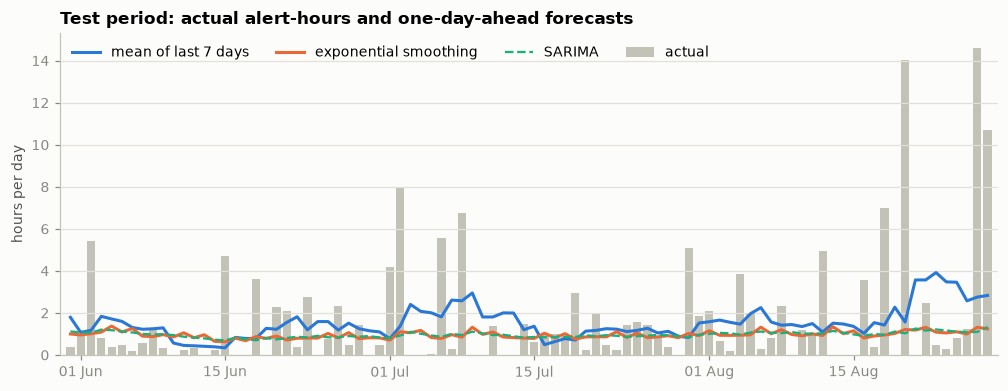

In [14]:
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(actual.index, actual.values, width=0.8, color=LIGHT, label="actual")
ax.plot(predictions.index, predictions["mean of last 7 days"], color=BLUE, label="mean of last 7 days")
ax.plot(predictions.index, predictions["exponential smoothing"], color=ORANGE, label="exponential smoothing")
ax.plot(predictions.index, predictions["SARIMA"], color=AQUA, lw=1.5, ls="--", label="SARIMA")
ax.set(title="Test period: actual alert-hours and one-day-ahead forecasts", ylabel="hours per day", xlim=(actual.index[0] - pd.Timedelta(days=1), actual.index[-1] + pd.Timedelta(days=1)))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.legend(ncol=4, loc="upper left")
plt.show()

**The result is weak: no method shows day-to-day forecasting skill.**

| Method | MAE | RMSE |
|---|---|---|
| Baseline: mean of last 7 days | 1.82 | 2.81 |
| Baseline: same weekday last week | 2.14 | 3.27 |
| Exponential smoothing | 1.59 | 2.85 |
| SARIMA | 1.60 | 2.87 |
| Reference: constant training median | 1.55 | 2.92 |
| Reference: constant training mean | 1.79 | 2.76 |

- **Against the two requested baselines,** both models have lower MAE (about 0.23 h better than the 7-day mean, interval −0.44 to −0.07) but slightly higher RMSE than the 7-day mean. Same-weekday-last-week is the worst method on both measures.
- **Against a constant, the models lose.** The training median has a lower MAE than either model, and the training mean has the lowest RMSE of all six rows. A model that cannot beat a constant has found no usable signal.
- **Why the models win on MAE.** Selection by validation MAE chose the log-transformed variants, whose forecasts are close to the median of a right-skewed series. Their forecasts barely move (s.d. about 0.15 h, against 2.8 h for the actuals), as the plot shows. The MAE gain over the 7-day mean comes from predicting a low, nearly constant value, not from anticipating heavy days.
- **The selection itself is not informative.** Within the log-transformed candidates the validation MAEs differ by a few thousandths of an hour, so the chosen orders (damped trend with a weekly term for exponential smoothing; ARIMA(0,1,1) on the log scale) are effectively arbitrary.
- **MAE and RMSE disagree,** and they reward different things: MAE the median, RMSE the mean. Had the settings been chosen by validation RMSE, different variants would have been picked. This was not run on the test period, to keep the test unused for selection.

This matches section 3: a lag-1 autocorrelation of about 0.13 leaves very little for a one-day-ahead model to use. The heavy days that matter most (14.0 h on 2026-08-20 and 14.6 h on 2026-08-27, the two heaviest days in the whole series) are not anticipated by any method.

## Forecast v2: is an alert about to begin?

v1 showed that the daily total is close to noise. v2 asks a shorter question: every 15 minutes between 18:00 and 06:00, what is the probability that Kyiv City is under alert at some instant in the next 15, 30, 60, 120 or 180 minutes? Definitions are in the README; the settings were selected on the 90 nights before the test period, committed, and the test period was then run once. This notebook only reads the saved results.

### Lead-lag between Kyiv City and the surrounding oblasts

Alert state (1 = active) sampled every 15 minutes from 2025-11-05 to 2026-05-31, with the mean for each quarter-hour of the day subtracted from every series, so that a shared night-time cycle is not counted as a relationship. A positive lag means the oblast leads Kyiv City.

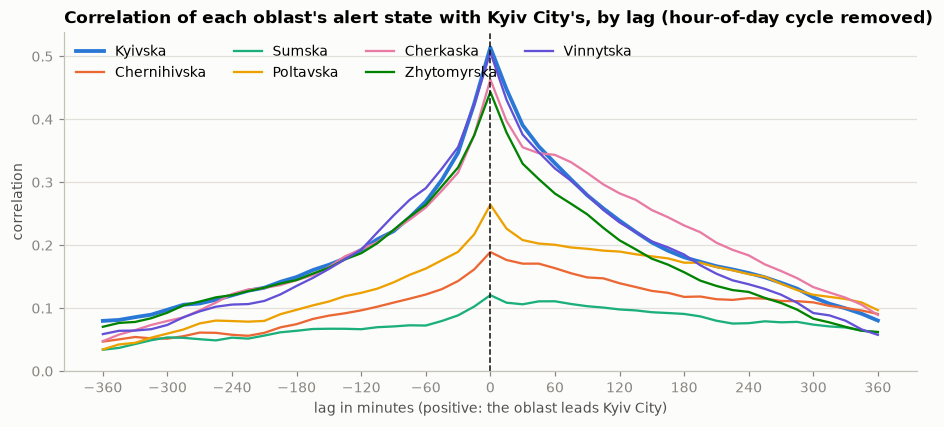

                     peak lag (min)   peak  oblast leads by 60 min  Kyiv leads by 60 min  oblast leads by 180 min  Kyiv leads by 180 min
Kyivska oblast                    0  0.514                   0.330                 0.269                    0.181                  0.149
Chernihivska oblast               0  0.189                   0.164                 0.122                    0.118                  0.075
Sumska oblast                     0  0.121                   0.111                 0.072                    0.091                  0.064
Poltavska oblast                  0  0.264                   0.201                 0.163                    0.172                  0.097
Cherkaska oblast                  0  0.463                   0.343                 0.260                    0.231                  0.144
Zhytomyrska oblast                0  0.443                   0.282                 0.264                    0.157                  0.145
Vinnytska oblast                  0  0.50

In [15]:
import json
from src import blocks, nowcast

RESULTS = Path.cwd().parent / "results" if Path.cwd().name == "notebooks" else Path.cwd() / "results"
PALETTE = [BLUE, ORANGE, AQUA, YELLOW, "#e87ba4", "#008300", "#6250d6"]

lead_lag = pd.read_csv(RESULTS / "nowcast_lead_lag.csv", index_col=0)
fig, ax = plt.subplots(figsize=(10, 4))
for name, colour in zip(lead_lag.columns, PALETTE):
    ax.plot(lead_lag.index, lead_lag[name], color=colour, lw=2.5 if name == "Kyivska oblast" else 1.5, label=name.replace(" oblast", ""))
ax.axvline(0, color=INK, lw=1, ls="--")
ax.set(title="Correlation of each oblast's alert state with Kyiv City's, by lag (hour-of-day cycle removed)",
       xlabel="lag in minutes (positive: the oblast leads Kyiv City)", ylabel="correlation", xticks=range(-360, 361, 60), ylim=(0, None))
ax.legend(ncol=4, loc="upper left")
plt.show()

summary = pd.DataFrame({"peak lag (min)": lead_lag.idxmax(), "peak": lead_lag.max(),
                        "oblast leads by 60 min": lead_lag.loc[60], "Kyiv leads by 60 min": lead_lag.loc[-60],
                        "oblast leads by 180 min": lead_lag.loc[180], "Kyiv leads by 180 min": lead_lag.loc[-180]})
print(summary.round(3).to_string())

- **Every oblast peaks at lag zero.** Alerts in Kyiv City and around it mostly begin within the same 15 minutes. That limits what the neighbours can say in advance.
- **The closest and the western and southern neighbours are the most related:** Kyivska 0.51, Vinnytska 0.51, Cherkaska 0.46, Zhytomyrska 0.44. Sumska (0.12) and Chernihivska (0.19) are the least, probably because they are under alert so much of the time that their state says little.
- **There is a slight asymmetry.** For every oblast the correlation is higher when the oblast leads than when Kyiv City leads (for Kyivska 0.33 against 0.27 at 60 minutes). That is the part a forecast can use, and it is small.
- These are correlations between strongly autocorrelated state series, so the curves are broad and neighbouring lags are not independent evidence.

### Selection (pre-test data only)

Three baselines: **(a)** trailing 90-day hour-of-day rate; **(b)** the same given whether Kyiv City is under alert now; **(c)** a logistic regression adding the time since Kyiv City's last alert ended. The model is (c) plus, per oblast, the minutes since its current alert started. The criterion is the mean Brier score over the five leads at issue times when Kyiv City is not under alert.

In [16]:
selection = json.loads((RESULTS / "nowcast_selection.json").read_text())
print(f"data known until {selection['data_known_until_utc']}; validation evenings {selection['validation_first_evening']} .. {selection['validation_last_evening']}")
print("\nbaseline (c) candidates:")
print(pd.DataFrame(selection["baseline_c_candidates"]).fillna("since switch").to_string(index=False, float_format="{:.4f}".format))
print("\nmodel candidates:")
print(pd.DataFrame(selection["model_candidates"]).fillna("since switch").to_string(index=False, float_format="{:.4f}".format))
print("\nchosen: baseline (c)", selection["baseline_c"], "| model", selection["model"])

data known until 2026-05-31 15:00:00+00:00; validation evenings 2026-03-02 .. 2026-05-30

baseline (c) candidates:
oblasts  window_days  val_brier
   none      60.0000     0.0693
   none      90.0000     0.0689
   none since switch     0.0688

model candidates:
oblasts  window_days  val_brier
kyivska      60.0000     0.0663
kyivska      90.0000     0.0661
kyivska since switch     0.0656
   ring      60.0000     0.0667
   ring      90.0000     0.0662
   ring since switch     0.0647
    all      60.0000     0.0710
    all      90.0000     0.0682
    all since switch     0.0671

chosen: baseline (c) {'oblasts': 'none', 'window_days': None} | model {'oblasts': 'ring', 'window_days': None}


The model with Kyivska and the six surrounding oblasts, trained on everything since the switch, is selected. For every oblast set the longest window is best, so the "recent window" ends up being all post-switch data. Using all 23 other oblasts overfits. The margins between the best candidates are small.

### Test period (run once)

Nights with evening dates 2026-05-31 to 2026-08-28. The headline table is for issue times when Kyiv City is **not** under alert, where the target means an alert starts within the lead time.

In [17]:
METHODS = ["a", "b", "c", "model"]
validation = pd.read_csv(RESULTS / "nowcast_validation_forecasts.csv", index_col=0, parse_dates=["night"])
test = pd.read_csv(RESULTS / "nowcast_test_forecasts.csv", index_col=0, parse_dates=["night"])
print(f"test: {test['night'].nunique()} nights, {len(test)} issue times, Kyiv City under alert at {test['kyiv_on'].mean():.1%} of them")

starts = nowcast.brier_table(test, METHODS, starts_only=True)
print("\nNot under alert at issue time (alert starts):")
print(starts[["n", "base_rate", "brier_a", "brier_b", "brier_c", "brier_model"]].round(4).to_string())
print("\nBrier skill:")
print(starts[["skill_b_vs_a", "skill_c_vs_b", "skill_model_vs_a", "skill_model_vs_b", "skill_model_vs_c"]].round(3).to_string())

everything = nowcast.brier_table(test, METHODS, starts_only=False)
print("\nAll issue times (target is 1 by definition when already under alert):")
print(everything[["n", "base_rate", "skill_b_vs_a", "skill_model_vs_a", "skill_model_vs_b", "skill_model_vs_c"]].round(3).to_string())

intervals = {ref: pd.DataFrame([nowcast.skill_interval(frame, lead, "model", ref) for lead in nowcast.LEADS],
                               index=nowcast.LEADS, columns=["skill", "low", "high"])
             for ref, frame in [("a", test), ("b", test), ("c", test)]}
print("\nModel skill with 95% intervals (nights resampled), not under alert:")
for ref, table in intervals.items():
    print(f"  against ({ref}): " + "; ".join(f"{lead} min {row.skill:+.3f} [{row.low:+.3f}, {row.high:+.3f}]" for lead, row in table.iterrows()))
val_c = pd.DataFrame([nowcast.skill_interval(validation, lead, "model", "c") for lead in nowcast.LEADS], index=nowcast.LEADS, columns=["skill", "low", "high"])
print("  validation, against (c): " + "; ".join(f"{lead} min {row.skill:+.3f}" for lead, row in val_c.iterrows()))

test: 90 nights, 4297 issue times, Kyiv City under alert at 9.3% of them

Not under alert at issue time (alert starts):
             n  base_rate  brier_a  brier_b  brier_c  brier_model
lead_min                                                         
15        3898      0.028    0.033    0.028    0.027        0.026
30        3897      0.055    0.056    0.052    0.052        0.050
60        3896      0.103    0.094    0.092    0.092        0.089
120       3895      0.187    0.151    0.151    0.149        0.147
180       3891      0.256    0.187    0.189    0.186        0.184

Brier skill:
          skill_b_vs_a  skill_c_vs_b  skill_model_vs_a  skill_model_vs_b  skill_model_vs_c
lead_min                                                                                  
15               0.161         0.004             0.190             0.035             0.031
30               0.072         0.006             0.113             0.044             0.038
60               0.019         0.010    


Model skill with 95% intervals (nights resampled), not under alert:
  against (a): 15 min +0.190 [+0.143, +0.251]; 30 min +0.113 [+0.070, +0.168]; 60 min +0.059 [+0.014, +0.113]; 120 min +0.024 [-0.028, +0.082]; 180 min +0.013 [-0.040, +0.071]
  against (b): 15 min +0.035 [+0.016, +0.055]; 30 min +0.044 [+0.016, +0.073]; 60 min +0.040 [+0.005, +0.075]; 120 min +0.029 [-0.012, +0.070]; 180 min +0.025 [-0.019, +0.073]
  against (c): 15 min +0.031 [+0.014, +0.048]; 30 min +0.038 [+0.015, +0.061]; 60 min +0.031 [+0.003, +0.060]; 120 min +0.017 [-0.019, +0.053]; 180 min +0.011 [-0.030, +0.053]
  validation, against (c): 15 min +0.029; 30 min +0.046; 60 min +0.055; 120 min +0.059; 180 min +0.068


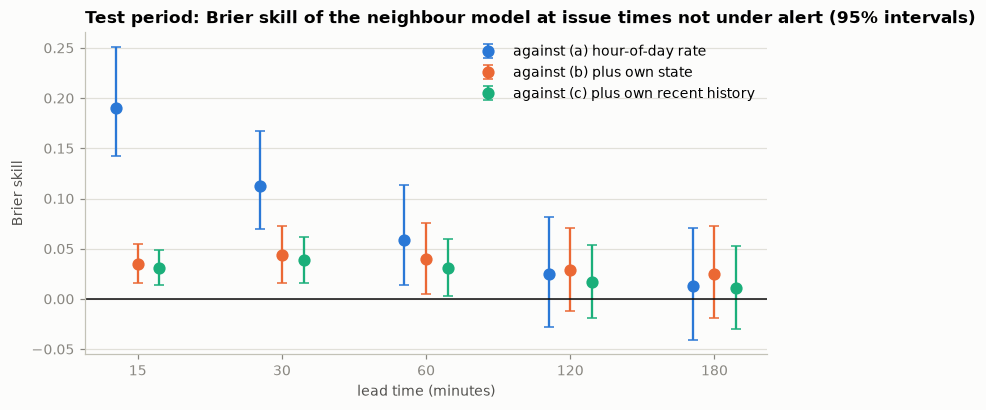

In [18]:
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(nowcast.LEADS))
for offset, (ref, colour, name) in zip((-0.15, 0, 0.15), [("a", BLUE, "(a) hour-of-day rate"), ("b", ORANGE, "(b) plus own state"), ("c", AQUA, "(c) plus own recent history")]):
    table = intervals[ref]
    ax.errorbar(x + offset, table["skill"], yerr=[table["skill"] - table["low"], table["high"] - table["skill"]],
                fmt="o", color=colour, ms=7, elinewidth=1.5, capsize=3, label=f"against {name}")
ax.axhline(0, color=INK, lw=1)
ax.set(title="Test period: Brier skill of the neighbour model at issue times not under alert (95% intervals)",
       xlabel="lead time (minutes)", ylabel="Brier skill", xticks=x, xticklabels=nowcast.LEADS)
ax.legend(loc="upper right")
plt.show()

**There is a small, real signal at short leads, and it fades by two hours.**

| Lead | Share with an alert start | Skill vs (a) | Skill vs (b) | Skill vs (c) | 95% interval vs (c) |
|---|---|---|---|---|---|
| 15 min | 2.8% | +0.19 | +0.035 | +0.031 | +0.014 to +0.048 |
| 30 min | 5.5% | +0.11 | +0.044 | +0.038 | +0.015 to +0.061 |
| 60 min | 10.3% | +0.06 | +0.040 | +0.031 | +0.003 to +0.060 |
| 120 min | 18.7% | +0.02 | +0.029 | +0.017 | −0.019 to +0.053 |
| 180 min | 25.6% | +0.01 | +0.025 | +0.011 | −0.030 to +0.053 |

- **Against the hardest baseline, (c),** the neighbour features improve the Brier score by about 3 to 4% at 15 to 60 minutes, with intervals that exclude zero. At 120 and 180 minutes the gain is 1 to 2% and the intervals include zero.
- **The test result is weaker than validation at long leads.** On validation the skill against (c) rose with lead time, to +0.068 at 180 minutes. On the test period it peaks at 30 minutes and falls. The long-lead validation skill did not carry over.
- **Kyiv City's own recent history adds almost nothing.** Baseline (c) beats (b) by 0.4 to 1.5%, with intervals that include zero.
- **Most of the skill against (a) is not forecasting.** At 15 minutes (b) already has +0.16 skill over (a) merely from setting aside issue times that are already under alert. Over all issue times the model's skill against (a) is +0.77 at 15 minutes; that only says that an ongoing alert continues.
- **The practical value is limited.** A 3% improvement in Brier score on an event with a base rate of 3 to 10% does not make a usable warning. This agrees with the lead-lag picture: alerts around Kyiv mostly begin at the same time as the city's.
- **The test period was busier than validation:** Kyiv City was under alert at 9.3% of issue times against 6.1%, and alert starts were about 1.7 times as frequent.

## Forecast v3: any alert in each 6-hour block of tomorrow

At midnight, give the probability of at least one alert in Kyiv City in each of 00-06, 06-12, 12-18 and 18-24 of the coming day. Every method is a rate over past days: the all-history block rate (baseline), trailing 7, 14, 21 or 30 days, and the same blended 50/50 with the rate in the 30 days around the same date a year earlier. Trailing rates are shrunk toward the all-history rate with a fixed prior of 7 days. A trailing 90-day rate is included as a reference. The window was selected on the 90 days before the test period; all methods were fixed in code and committed before the test period was run, once.

The same 90 test days had already been scored in v1 and v2, so they were not unseen when v3 was designed.

In [19]:
block_selection = json.loads((RESULTS / "blocks_selection.json").read_text())
print("validation (90 days before the test period):")
print(pd.DataFrame(block_selection["candidates"])[["method", "val_brier"]].to_string(index=False, float_format="{:.4f}".format))
chosen = block_selection["chosen_label"]
print("selected:", chosen)

block_test = pd.read_csv(RESULTS / "blocks_test_forecasts.csv", parse_dates=["day"])
methods = [c for c in block_test.columns if c not in ("day", "block", "y", "on_at_midnight")]
print(f"\ntest: {block_test['day'].nunique()} days, {len(block_test)} forecasts; share of blocks with an alert: "
      + ", ".join(f"{int(b):02d}-{int(b) + 6:02d} {rate:.0%}" for b, rate in block_test.groupby('block')['y'].mean().items()))
scores = blocks.score_table(block_test, methods)
print(scores.to_string(float_format="{:.4f}".format))
for reference in ("all history", "trailing 90d"):
    value, low, high = blocks.skill_interval(block_test, chosen, reference)
    print(f"selected ({chosen}) against {reference}: skill {value:+.3f}  [{low:+.3f}, {high:+.3f}]")

print("\nby block, skill of the selected method against the baseline:")
for block, rows in block_test.groupby("block"):
    print(f"  {int(block):02d}-{int(block) + 6:02d}: {blocks.score_table(rows, [chosen]).loc[chosen, 'skill_vs_baseline']:+.3f}")
night = block_test[block_test["block"] == 0]
for running, rows in night.groupby("on_at_midnight"):
    table = blocks.score_table(rows, ["all history", chosen])
    print(f"  00-06, alert running at midnight = {running}: {len(rows)} days, alert in block on {rows['y'].mean():.0%}; "
          f"Brier baseline {table.loc['all history', 'brier']:.3f}, selected {table.loc[chosen, 'brier']:.3f}")

validation (90 days before the test period):
                  method  val_brier
             all history     0.2131
            trailing 90d     0.2144
             trailing 7d     0.2243
            trailing 14d     0.2168
            trailing 21d     0.2165
            trailing 30d     0.2177
 trailing 7d + last year     0.2247
trailing 14d + last year     0.2209
trailing 21d + last year     0.2212
trailing 30d + last year     0.2222
selected: trailing 21d

test: 90 days, 360 forecasts; share of blocks with an alert: 00-06 49%, 06-12 33%, 12-18 29%, 18-24 38%
                          brier  skill_vs_baseline  skill_vs_reference
method                                                                
all history              0.2333             0.0000             -0.0011
trailing 90d             0.2330             0.0011              0.0000
trailing 7d              0.2363            -0.0131             -0.0142
trailing 14d             0.2370            -0.0162             -0.0174
trail

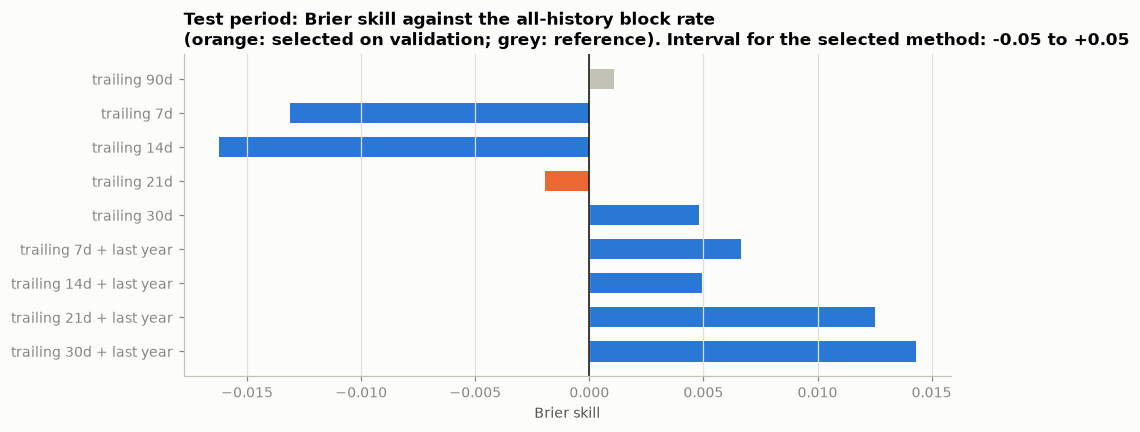

In [20]:
fig, ax = plt.subplots(figsize=(9, 3.8))
order = [m for m in methods if m != "all history"]
values = scores.loc[order, "skill_vs_baseline"]
colours = [ORANGE if m == chosen else (LIGHT if m == "trailing 90d" else BLUE) for m in order]
ax.barh(order[::-1], values[::-1], color=colours[::-1], height=0.6)
ax.axvline(0, color=INK, lw=1)
ax.set(title="Test period: Brier skill against the all-history block rate\n(orange: selected on validation; grey: reference). Interval for the selected method: -0.05 to +0.05", xlabel="Brier skill")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
plt.show()

**No skill.** The selected method, the trailing 21-day rate, scores a Brier of 0.2337 against 0.2333 for the all-history rate: skill −0.002, with a 95% interval of −0.05 to +0.05.

- **Nothing beat the baseline on validation either.** The all-history rate had the lowest validation Brier of all ten methods, so the selection only picked the least bad candidate.
- **All methods are close to uninformative.** A Brier score of 0.23 is barely below the 0.25 of always saying 50%. In the test period 37% of blocks had an alert, so "any alert in a 6-hour block" is close to a coin flip that these rates cannot call.
- **The last-year variants look best on the test period (up to +0.014) and should not be believed.** They were the worst on validation, the differences are far inside the interval above, and section 2 found no reliable yearly pattern. Reporting them as a success would be choosing a method after seeing the test.
- **The trailing 90-day reference is no better than all history** (skill +0.001), so in this period even the level drift from section 3 gave nothing.
- **By block,** the selected method is ahead in 00-06 (+0.06) and behind in the other three. With 90 days per block these are not reliable differences.
- **Alert running at midnight:** this happened on 4 of the 90 days, and the 00-06 outcome is then 1 by definition. On the other 86 days the picture is the same as overall.

Together with v1 this is consistent: for Kyiv City, the history of alerts says very little about tomorrow, whether the target is hours or occurrence.

## Limitations

- **One source, not independently verified.** All figures come from one pinned file. Whether long frontline alerts are real is inferred from where they are, not checked against another source.
- **Feed break.** The analysis ends on 2026-08-28. The file's own irregularities (a concatenated older export, a 4.4-day outage) suggest other, smaller gaps could exist; none longer than 19 hours nationwide was found.
- **Alert time is not attack intensity.** An alert records a threat declared for an area, and declaration practice changed over the period.
- **Few annual cycles.** 2.7 years of data cannot establish or exclude a modest yearly pattern.
- **One test window.** Forecast scores come from a single 90-day period that contains the two heaviest days of the whole series (2026-08-20 and 2026-08-27); RMSE in particular is driven by a handful of days.
- **Heavy days just before the feed break.** Those two days fall in the last nine days before the outage. Their rows look ordinary (many separate alerts of normal length), but this analysis cannot rule out that the feed was already misbehaving.
- **Descriptive sections use the full series,** including the forecast test period. Nothing from them was used to choose forecast settings: the weekly period of 7 was fixed in advance and all other settings were selected by code on data before the test period.
- **v2 and v3 share the v1 test period.** The 90 days were first scored in v1. For v2 and v3 the settings were fixed and committed before each test run, but the period was no longer unseen.
- **v2 assumes real-time publication.** An alert's start is treated as known at its start time. If the feed records starts late, the measured skill is too high.
- **v2 has no threat type.** The file does not say why an alert was declared, which is probably the most useful missing input.
- **v2 uses post-switch data only,** about 200 nights before the test period.